## Imports

In [1]:
# Run this cell to install the required packages
# import Pkg
# packages = [
#     "MathieuFunctions",
#     "DataFrames",
#     "CSV",
#     "LinearAlgebra",
#     "Random",
#     "Distributions",
#     "Interpolations",
#     "ProgressMeter",
#     "FFTW",
#     "DSP",
#     "Colors",
#     "NonlinearSolve",
#     "Printf",
#     "FileIO",
#     "NaNMath",
#     "GeometryBasics",
#     "Makie",
#     "GLMakie",
#     "CairoMakie",
# ]
# Pkg.add(packages)

In [2]:
using MathieuFunctions, 
DataFrames, 
CSV,
LinearAlgebra, 
Random, 
Distributions, 
Interpolations, 
ProgressMeter,
FFTW,
DSP,
Colors,
NonlinearSolve,
Printf, 
FileIO,
NaNMath

using GeometryBasics
using Distributions: Normal

using Makie; using Makie: Axis
import GLMakie, CairoMakie
CairoMakie.activate!()

##  Functions

### General

In [3]:
function plotStabilityRegion(V_RF, V_EC; M=1.0, Ω=1.0, z₀=1.0, r₀=1.0, Q=1.0, κ=1.0, η=1.0, ϵ=0.5)
    ξ = -M*Ω^2*z₀^2 / (8*Q*κ*ϵ)
    ϐ = M*Ω^2*r₀^2 / (2*Q*η)

    qs = LinRange(0.0, 1.5, 1000)
    a_x0 = ξ.*[charA(q, k=0:0)[1] for q in qs]
    b_x1 = ξ.*[charB(q, k=1:1)[1] for q in qs]
    
    # ideal 3D trap
    # a_y0 = [-2*charA(q/2, k=0:0)[1] for q in qs]  # a_z = -2 * a_x
    # b_y1 = [-2*charB(q/2, k=1:1)[1] for q in qs]  # q_x = 1/2 * q_z

    # ideal linear trap
    # a_y0 = [-charA(q, k=0:0)[1] for q in qs]  # a_y = -2 * a_x
    # b_y1 = [-charB(q, k=1:1)[1] for q in qs]  # q_x = q_y

    # our trap
    a_y0 = ξ.*[(1/ϵ - 1)*charA(q, k=0:0)[1] for q in qs] # a_y = a_x * (1/ϵ - 1)
    b_y1 = ξ.*[(1/ϵ - 1)*charB(q, k=1:1)[1] for q in qs] # q_x = q_y
    a_z0 = ξ.*[(-1/ϵ)*charA(q*0, k=0:0)[1] for q in qs] # a_z = a_x * -1/ϵ
    b_z1 = ξ.*[(-1/ϵ)*charB(q*0, k=1:1)[1] for q in qs] # q_z = 0
    
    qs = ϐ.*qs

    fig = Figure(); 
    ax  = CairoMakie.Axis(
        fig[1, 1],
        title = "Stability region, ϵ = $ϵ", titlesize= 20,
        xlabel = L"V_{RF}", xlabelsize= 25,
        ylabel = L"V_{EC}", ylabelsize= 25,
    )
    lines!(ax, qs, a_x0, color=:firebrick1, label="x stability")
    lines!(ax, qs, b_x1, color=:firebrick1)

    lines!(ax, qs, a_y0, color=:forestgreen, label="y stability")
    lines!(ax, qs, b_y1, color=:forestgreen)

    lines!(ax, qs, a_z0, color=:dodgerblue3, label="z stability")
    lines!(ax, qs, b_z1, color=:dodgerblue3)

    z_high = max.(a_x0, b_x1)
    y_high = max.(a_y0, b_y1)
    a_high = min.(z_high, y_high)

    z_low = min.(a_x0, b_x1)
    y_low = min.(a_y0, b_y1)
    a_low = max.(z_low, y_low)

    # only for our trap
    a_low = max.(a_low, a_z0)

    mask = a_low .> a_high
    a_low[mask] .= NaN
    a_high[mask] .= NaN

    band!(ax, qs, a_low, a_high, color="#546865", alpha=0.6)

    axislegend(ax, position = :lt)

    scatter!(ax, V_RF, V_EC, color=:black, markersize=10)
    ylims!(-0.4*ϐ, 0.8*ϐ)

    return fig, ax
end

function simulate(ts, t_total, r₀, v₀, γ, M, k_b, T, F)
    Δt = step(ts); n_t = length(ts)
    r_t = zeros(n_t, 3)
    v_t = zeros(n_t, 3)

    r_t[1,:] = r₀
    v_t[1,:] = v₀

    a = (1-γ*Δt/(2*M))/(1+γ*Δt/(2*M))
    b = 1/(1+γ*Δt/(2*M))
    σ = sqrt(2*γ*k_b*T*Δt)
    Δη_all = rand(Normal(0,σ), (n_t-1, 3))

    @showprogress for i = 1 : n_t-1
        t = ts[i]
        Fᵢ = F(r_t[i,:], t)
        r_t[i+1,:] = r_t[i,:] + v_t[i,:]*b*Δt  + b/(2*M)*Fᵢ*Δt^2 + b/(2*M)*Δη_all[i,:]*Δt 
        
        Fᵢ₊₁ = F(r_t[i+1,:], t+Δt)
        v_t[i+1,:] = a*v_t[i,:] + 1/(2*M)*(a*Fᵢ + Fᵢ₊₁)*Δt + b/M*Δη_all[i,:]
    end

    return r_t, v_t
end

function importComsolField3D(nx, ny, nz, path, cols=3; start=1, skipto=10, type="spreadsheet")
    if type == "spreadsheet"
        raw_data = Matrix(
            CSV.read(
                path,
                DataFrame;
                delim = ';',
                header = false,
                skipto = skipto
            )
        )

        Fs = zeros(nx, ny, nz, cols)

        row = 1
        for k = 1:nz, j = 1:ny, i = 1:nx
            for col in 1:cols
                Fs[i, j, k, col] = raw_data[row, start+col-1]
            end
            row += 1
        end
    elseif type == "grid" 
    end

    return Fs
end

function getPSD(r_t, Δt; fs_obj=nothing, fmin=1.0, fmax=nothing,
                fs_use=nothing, winlen=nothing, start_idx=nothing,
                window_type::Symbol = :hann)

    fs_real = fs_use === nothing ? 1/Δt : fs_use
    if fs_obj === nothing
        fs_obj = fs_real
    end
    step = floor(Int, fs_real / fs_obj)
    fs = fs_real / step

    x_full = r_t[1:step:end, 1]
    y_full = r_t[1:step:end, 2]
    z_full = r_t[1:step:end, 3]

    N_total = length(x_full)

    if winlen === nothing
        winlen = N_total
    end
    winlen = min(winlen, N_total)

    if start_idx === nothing
        start_idx = N_total - winlen + 1
    end
    start_idx = max(1, start_idx)
    end_idx = min(start_idx + winlen - 1, N_total)

    x = x_full[start_idx:end_idx]
    y = y_full[start_idx:end_idx]
    z = z_full[start_idx:end_idx]

    N_used = length(x)

    w = window_type === :hann ? DSP.hann(N_used) : ones(eltype(x), N_used)

    px = periodogram(x .* w; fs=fs)
    py = periodogram(y .* w; fs=fs)
    pz = periodogram(z .* w; fs=fs)

    freqs = freq(px)
    psd_x = power(px)
    psd_y = power(py)
    psd_z = power(pz)

    if fmax === nothing
        fmax = maximum(freqs)
    end

    freq_mask = (freqs .>= fmin) .& (freqs .<= fmax)
    freqs_filtered = freqs[freq_mask]
    psd_x_filtered = psd_x[freq_mask]
    psd_y_filtered = psd_y[freq_mask]
    psd_z_filtered = psd_z[freq_mask]

    psds = hcat(psd_x_filtered, psd_y_filtered, psd_z_filtered)

    Δf = fs / N_used
    println("FFT Δf = $(Δf) Hz, muestras totales = $(N_total), usadas = $(N_used)")

    return freqs_filtered, psds
end

function getEfficiencyFactor(type, V, us, Φs, u₀; u_0=[[1/2,0], [1/2,0]], return_fig=false)
    if type == "κ"
        Φ_EC⁽ᶻ⁾(z, κ, V_EC, z₀) = κ * V_EC / z₀^2 * z^2
        p = (V_EC=V, z₀=u₀, zs=us, Φs=Φs)

        function residuals(u, p)
            κ = u[1]
            offset = u[2]
            return Φ_EC⁽ᶻ⁾.(p.zs, κ, p.V_EC, p.z₀) .- p.Φs .+ offset
        end

        LSQ_problem = NonlinearLeastSquaresProblem(residuals, u_0[1], p)
        sol = solve(LSQ_problem)
        κ_est = sol.u[1]

        fig, ax = plotEfficiencyFactor(type, "z", us, Φs, Φ_EC⁽ᶻ⁾.(us, κ_est, V, u₀) .+ sol.u[2], κ_est)
        display(fig)
        if return_fig
            return κ_est, fig, ax
        else
            return κ_est
        end
    elseif type == "η"
        Φs_x = Φs[1]; Φs_y = Φs[2]
        xs   = us[1]; ys   = us[2]

        Φ_RF⁽ˣ⁾(x, η, V_RF, r₀) =  η * V_RF / 2r₀^2 * x^2
        Φ_RF⁽ʸ⁾(y, η, V_RF, r₀) = -η * V_RF / 2r₀^2 * y^2
        px = (V_RF=V, r₀=u₀, xs=xs, Φs_x=Φs_x)
        py = (V_RF=V, r₀=u₀, ys=ys, Φs_y=Φs_y)

        function residualsX(u, p)
            η = u[1]
            offset = u[2]
            return Φ_RF⁽ˣ⁾.(p.xs, η, p.V_RF, p.r₀) .- p.Φs_x .+ offset
        end
        function residualsY(u, p)
            η = u[1]
            offset = u[2]
            return Φ_RF⁽ʸ⁾.(p.ys, η, p.V_RF, p.r₀) .- p.Φs_y .+ offset
        end

        LSQ_problem_x = NonlinearLeastSquaresProblem(residualsX, u_0[2], px)
        LSQ_problem_y = NonlinearLeastSquaresProblem(residualsY, u_0[2], py)
        sol_x = solve(LSQ_problem_x); sol_y = solve(LSQ_problem_y)
        η_est_x = sol_x.u[1]; η_est_y = sol_y.u[1]
        fig, ax = plotEfficiencyFactor("x: η", "Position", xs, Φs_x, Φ_RF⁽ˣ⁾.(xs, η_est_x, V, u₀) .+ sol_x[2], η_est_x)
        fig, ax = plotEfficiencyFactor("y: η", "", ys, Φs_y, Φ_RF⁽ʸ⁾.(ys, η_est_y, V, u₀) .+ sol_y[2], η_est_y; 
                                        hold=true, fig=fig, ax=ax, title = "Curve Fitting to Obtain $(type)",
                                        color1=Makie.wong_colors()[3], color2=Makie.wong_colors()[4])
        display(fig)
        if return_fig
            return mean([η_est_x, η_est_y]), fig, ax
        else
            return mean([η_est_x, η_est_y])
        end
    else
        @warn "Invalid type \"$(type)\""
        return
    end
end

getEfficiencyFactor (generic function with 1 method)

### Graphics

In [4]:
function plot3dTraj(r_t; step=50, r₀=nothing, lw=3, showTrap=false, r_0=nothing, z_0=nothing, r_e=nothing, θ₀=0, trap_path=nothing)
    CairoMakie.activate!()
    fig = Figure()
    ax = Axis3(fig[1, 1];
        viewmode = :free, 
        aspect = :data,
        zoommode = :cursor,
        xlabel = "x (mm)", ylabel = "y (mm)", zlabel = "z (mm)",
        title = "Trajectory of the particle")
    if r₀ !== nothing
        scatter!(ax, [r₀[1]*1000], [r₀[2]*1000], [r₀[3]*1000], color=:red, markersize=10)
    end

    t = (0:step:size(r_t, 1)-1) / size(r_t, 1)
    lines!(ax, r_t[1:step:end,:].*1000, color=t, linewidth=lw, colormap=:viridis)

    if showTrap && r_0 !== nothing  && r_e !== nothing && trap_path == nothing
        if z_0 === nothing
            z_0 = 5*maximum(abs.(r_t[:, 3]))
        end
        r_0 *= 1000; z_0 *= 1000; r_e *= 1000;
        rc = r_0 + r_e
        col_i = 0;
        for θ in (θ₀ .+ [0, π/2, π, 3π/2])
            𝒪 = Point3(rc*cos(θ), rc*sin(θ), -z_0)
            ℰ = Point3(rc*cos(θ), rc*sin(θ),  z_0)
            cyl = Cylinder(𝒪, ℰ, r_e)
            cyL = GeometryBasics.mesh(cyl)

            col_i+=1
            col = col_i%2==0 ? :dodgerblue3 : :firebrick1
            mesh!(ax, cyl; color=col, alpha=0.5, transparency=true)
        end
    elseif showTrap && trap_path !== nothing
        trap = load(trap_path)
        mesh!(ax, trap; alpha=0.5, transparency=true)
    end
    
    
    display(GLMakie.Screen(), fig.scene)
    return fig, ax
end

function plot1dTraj(r_t, ts; step=50, dim="position", extra="", hold=false, fig=nothing, ax=nothing)
    CairoMakie.activate!()
    if ~hold
    fig = Figure()
    ax = Axis(fig[1, 1];
        xlabel = "Time (ms)", ylabel = "$(dim) (mm)",
        title = "Trajectory of the Particle $(extra)")
    else
        @assert fig!=nothing && ax!=nothing "You must provide existing fig and ax"
    end
    lines!(ax, ts[1:step:end].*1000, r_t[1:step:end].*1000)
    display(fig)
    return fig, ax    
end

function plot2dTraj(r_t, ts, dims; step=50, dimx="position", dimy="position", limits=(nothing, nothing))
    CairoMakie.activate!()
    fig = Figure()
    ax = Axis(fig[1, 1];
        xlabel = "$(dimx) (mm)", ylabel = "$(dimy) (mm)",
        title = "Trajectory of the Particle",
        limits = limits)

    t = ts[1:step:end] / ts[end]
    lines!(ax, r_t[1:step:end, dims[1]].*1000, r_t[1:step:end, dims[2]].*1000; color = t, colormap=:viridis)
    display(fig)
    return fig, ax    
end

function plotPSD(freqs, psds; step=100)
    CairoMakie.activate!()
    fmin = minimum(freqs)
    fmax = maximum(freqs)

    # Create plot
    fig = Figure()
    ax = Axis(fig[1, 1],
        xscale=log10, yscale=log10,
        xlabel="Frequency [Hz]",
        ylabel="PSD [m²/Hz]",
        title="Power Spectral Density of Particle Trajectory"
    )
    
    # Plot PSD for each dimension
    lines!(ax, freqs[1:step:end], psds[1:step:end, 1], color=:firebrick1, linewidth=2, label="x")
    lines!(ax, freqs[1:step:end], psds[1:step:end, 2], color=:forestgreen, linewidth=2, label="y") 
    lines!(ax, freqs[1:step:end], psds[1:step:end, 3], color=:dodgerblue3, linewidth=2, label="z")
    
    # Add legend
    axislegend(ax, position=:rt)
    
    # Set limits
    xlims!(ax, fmin, fmax)
    
    display(fig)
    return fig, ax
end

function plotFieldSlice(xs, ys, field; title="Field Magnitude at z=0 mm", xlabel="x (mm)", ylabel="y (mm)", colormap = :viridis)
    CairoMakie.activate!()
    fig = Figure()
    ax = Axis(fig[1, 1],
        title=title,
        xlabel=xlabel,
        ylabel=ylabel,
        aspect=DataAspect()
    )
    hm = heatmap!(ax, xs.*1000, ys.*1000, field'; colormap=colormap)
    Colorbar(fig[1, 2], hm; label="Field Magnitude", width=15)
    display(fig)
    return fig, ax
end

function plotEfficiencyFactor(type, dim, us, Φs, Φ_curve, est; 
                                markersize = 5, hold=false, fig=nothing, ax=nothing,
                                color1=:dodgerblue3, color2=:firebrick1, title="Multiple plots")
    CairoMakie.activate!()
    if ~hold
        fig = Figure()
        ax  = Axis(fig[1, 1];
                xlabel = "$(dim) (mm)", xlabelsize=20,
                ylabel = "Electric potential (V)", ylabelsize=20,
                title = "Curve Fitting to Obtain $(type)", titlesize=20)
    else 
        @assert fig!=nothing && ax!=nothing && title!=nothing "You must provide existing fig and ax"
        ax.title = title
    end
    scatter!(ax, us.*1e3, Φs, markersize=markersize, label="COMSOL data", color=color1)
    lines!(ax, us.*1e3, Φ_curve, label="$(type) = $(round(est, digits=3))", color=color2)
    axislegend(ax);
    return fig, ax
end

function plotfvsV_RF(f_range, V_RF_range, Q╱M, η, κ, r_0, z_0, V_EC, V_RF, f; 
            colormap=:viridis, 
            res=500, 
            interactive=true,
            r_0_range=(0.5:0.01:2),
            Q╱M_range=((8.7e-8)*1e3:(1e-8):(0.0076)*1e3),
            V_EC_range=(0:1:100)
            )
    GLMakie.activate!()
    fs = LinRange(f_range[1], f_range[2], res)
    V_RFs = LinRange(V_RF_range[1], V_RF_range[2], res)

    # Observables
    ## Sliders
    r_0_obs = Observable(r_0)
    Q╱M_obs  = Observable(Q╱M)
    V_EC_obs = Observable(V_EC)

    ## Frequency map of q_x
    qs_obs = @lift begin
        q = [2V_RF*η / ((2π*f)^2 * $r_0_obs^2) * $Q╱M_obs
             for V_RF in V_RFs, f in fs]
        q[q .> 0.908] .= NaN
        q'
    end

    ## Isocurves of adiabatic limit and ω_x=0
    adiab_obs = @lift @. ((2V_RFs*η)/((0.2)*$r_0_obs^2)*$Q╱M_obs)^(1/2)/2π * 1e-3
    ω_0_obs = @lift @. ((2*$V_EC_obs*κ)/(z_0^2*$Q╱M_obs))^(1/2)*$r_0_obs^2/η * 2π * fs

    ## Frequency map of ω_x
    ω_x_obs = @lift begin
        a_x(f) = -(4*$Q╱M_obs*$V_EC_obs*κ)/((2π*f)^2*z_0^2)
        q_x(f, V_RF) = (2*$Q╱M_obs*V_RF*η)/((2π*f)^2*$r_0_obs^2)
        ω_x =  [(2π*f)/2 * NaNMath.sqrt(a_x(f) + q_x(f, V_RF)^2/2) for V_RF in V_RFs, f in fs] / 2π * 1e-3
        ω_x[isnan.($qs_obs')] .= NaN
        ω_x'
    end

    ## Current operating point info
    ### Label
    V_RF_obs = Observable(V_RF)
    f_obs = Observable(f)
    a_x_obs = @lift -(4*$Q╱M_obs*$V_EC_obs*κ)/((2π*$f_obs)^2*z_0^2)
    q_x_obs = @lift  (2*$Q╱M_obs*$V_RF_obs*η)/((2π*$f_obs)^2*$r_0_obs^2)
    ω_x_here_obs = @lift (2π*$f_obs)/2 * NaNMath.sqrt($a_x_obs + $q_x_obs^2/2)
    info_obs = @lift @sprintf("\n\n\n\n\n\n\n\n\n Current Operating Point:
                            \nV_RF = %.2f kV
                            \nΩ/2π = %.2f kHz
                            \nωₓ/2π = %.3f kHz
                            \naₓ = %.3f
                            \nqₓ = %.3f", 
                            $V_RF_obs*1e-3, $f_obs*1e-3,
                            $ω_x_here_obs / 2π * 1e-3, 
                            $a_x_obs, $q_x_obs)
    ### Draggable point
    cursor = Observable([Point2f(f_obs[]*1e-3, V_RF_obs[])])
    cursor_color = Observable(:black)

    # Figure
    fig = Figure()
    ax = Axis(fig[1, 1],
        title="Operation Parameters Map (η=$(round(η, digits=3)), κ=$(round(κ, digits=3)), z₀=$(round(z_0, digits=3)))", titlesize=15,
        xlabel=L"\Omega/2\pi\,\, \mathrm{(kHz)}", xlabelsize=20,
        ylabel=L"V_{RF}\,\, \mathrm{(V)}", ylabelsize=20
    )
    
    # Contour plot of q_x
    hm = contourf!(ax, fs.*1e-3, V_RFs, qs_obs; colormap=colormap, levels=0:0.1:0.9)
    Colorbar(fig[1, 2], hm; label=L"q_x", labelsize=20, ticks=0:0.1:1)

    # Isocurves of adiabatic limit and ω_x=0
    lines!(ax, adiab_obs, V_RFs; color=:red, linewidth=1.5, linestyle=:dash, label="Adiabatic Limit")
    lines!(ax, fs.*1e-3, ω_0_obs; color=:white, linewidth=1.5, linestyle=:dash, label="ωₓ/2π (kHz)")

    # Isocurves of ω_x
    valid_ω_x = filter(!isnan, ω_x_obs[])
    levels_ω_x = quantile(valid_ω_x, LinRange(0.05, 0.95, 10))
    ctr = contour!(ax, fs.*1e-3, V_RFs, ω_x_obs; levels=levels_ω_x, color=:white, labels=true, linestyle=:dash, linewidth=1.5, labelfont = :bold, labelsize = 15)

    # Current operating point
    sc = scatter!(ax, cursor, color=cursor_color, markersize=15, label="Current Point")

    # Set limits and legend
    xlims!(ax, f_range[1]*1e-3, f_range[2]*1e-3)
    ylims!(ax, V_RF_range[1], V_RF_range[2])
    axislegend(ax, position=:lt, backgroundcolor=:gray85, framecolor=(:gray85, 0.5));

    # Interactive
    if interactive
        resize!(fig.scene, (3000, 2000))

        # Right panel for sliders and info
        right_panel = GridLayout(fig[1, 3]; tellheight=false)
        Label(right_panel[1, 1], info_obs;
            tellwidth=false,
            fontsize=15,
            font=:bold,
            halign=:center, valign=:center,
            color=:gray30,
            padding=(10, 0, 8, 8),
        )

        # Sliders
        sg = SliderGrid(
            right_panel[2, 1],
            (label = "r_0", range = r_0_range, format = "{:.2f} mm", startvalue = r_0*1e3),
            (label = "Q/M", range = Q╱M_range, format = "{:.2f} mC/kg", startvalue = Q╱M*1e3),
            (label = "V_EC", range = V_EC_range, format = "{:.2f} V", startvalue = V_EC),
            width = 350,
            tellheight = false
        )
        on(sg.sliders[1].value) do val
            r_0_obs[] = val * 1e-3   # mm -> m
        end
        on(sg.sliders[2].value) do val
            Q╱M_obs[] = val * 1e-3   # mC/kg -> C/kg
        end
        on(sg.sliders[3].value) do Val
            V_EC_obs[] = Val
        end

        # Draggable point to adjust current operating point
        dragging = Ref(false)
        idx = Ref(1)
        on(events(fig).mousebutton, priority=2) do event
            if event.button == Mouse.left
                if event.action == Mouse.press
                    plt, i = pick(fig)
                    dragging[] = plt == sc
                    idx[] = i
                    cursor_color[] = dragging[] ? :gray40 : :black
                    return Consume(dragging[])
                elseif event.action == Mouse.release
                    dragging[] = false
                    cursor_color[] = :black
                    return Consume(false)
                end
            end
            return Consume(false)
        end
        on(events(fig).mouseposition, priority=2) do mp
            if dragging[]
                pt = mouseposition(ax)
                cursor[][idx[]] = pt
                notify(cursor)
        
                f_obs[]    = pt[1] * 1e3  
                V_RF_obs[] = pt[2]        
                return Consume(true)
            end
            return Consume(false)
        end
        
        # Button to reset sliders
        btt = Button(right_panel[3, 1]; label="Reset", tellwidth=false)
        on(btt.clicks) do _
            set_close_to!(sg.sliders[1], r_0 * 1e3)
            set_close_to!(sg.sliders[2], Q╱M * 1e3)
            set_close_to!(sg.sliders[3], V_EC)
            V_RF_obs[] = V_RF
            f_obs[] = f
            cursor[][1] = Point2f(f_obs[]*1e-3, V_RF_obs[]) 
            notify(cursor)
        end

        # Show fig
        display(GLMakie.Screen(), fig.scene)
    else
        CairoMakie.activate!()
        display(fig)
    end
end     

function plotf_secvsV_RF(f_range, V_RF_range, Q╱M, η, κ, r_0, z_0, V_EC, V_RF, f; 
            colormap=:viridis, 
            res=500, 
            interactive=true,
            r_0_range=(0.5:0.01:2),
            Q╱M_range=((8.7e-8)*1e3:(1e-8):(0.0076)*1e3),
            V_EC_range=(0:1:100)
            )
    GLMakie.activate!()
    fs = LinRange(f_range[1], f_range[2], res)
    V_RFs = LinRange(V_RF_range[1], V_RF_range[2], res)

    # Observables
    ## Sliders
    r_0_obs = Observable(r_0)
    Q╱M_obs  = Observable(Q╱M)
    V_EC_obs = Observable(V_EC)

    ## Frequency map of q_x
    qs_obs = @lift begin
        q = [4*$r_0_obs^2*((2π*f)^2*z_0^2+$Q╱M_obs*$V_EC_obs*κ) / ($Q╱M_obs*V_RF*η*z_0^2)
             for V_RF in V_RFs, f in fs]
        q[q .> 0.908] .= NaN
        q
    end

    ## Frequency map of Ω
    Ω_obs = @lift begin
        q_x(f, V_RF) = 4*$r_0_obs^2*((2π*f)^2*z_0^2+$Q╱M_obs*$V_EC_obs*κ) / ($Q╱M_obs*V_RF*η*z_0^2)
        Ω =  [NaNMath.sqrt((2*$Q╱M_obs*V_RF*η)/(q_x(f, V_RF)*$r_0_obs^2))
             for V_RF in V_RFs, f in fs] / 2π * 1e-3
        Ω[isnan.($qs_obs)] .= NaN
        Ω
    end

    ## Current operating point info
    ### Label
    V_RF_obs = Observable(V_RF)
    f_obs = Observable(f)
    q_x_obs = @lift 4*$r_0_obs^2*((2π*$f_obs)^2*z_0^2+$Q╱M_obs*$V_EC_obs*κ) / ($Q╱M_obs*$V_RF_obs*η*z_0^2)
    Ω_here_obs = @lift (NaNMath.sqrt((2*$Q╱M_obs*$V_RF_obs*η)/($q_x_obs*$r_0_obs^2)))
    a_x_obs = @lift -(4*$Q╱M_obs*$V_EC_obs*κ)/(($Ω_here_obs)^2*z_0^2)
    info_obs = @lift @sprintf("\n\n\n\n\n\n\n\n\n Current Operating Point:
                            \nV_RF = %.2f kV
                            \nΩ/2π = %.2f kHz
                            \nωₓ/2π = %.3f kHz
                            \naₓ = %.3f
                            \nqₓ = %.3f", 
                            $V_RF_obs * 1e-3, $Ω_here_obs / 2π * 1e-3, 
                            $f_obs * 1e-3, $a_x_obs, $q_x_obs)
    ### Draggable point
    cursor = Observable([Point2f(V_RF_obs[], f_obs[]*1e-3)])
    cursor_color = Observable(:black)

    # Figure
    fig = Figure()
    ax = Axis(fig[1, 1],
        title="Operation Parameters Map (η=$(round(η, digits=3)), κ=$(round(κ, digits=3)), z₀=$(round(z_0, digits=3)))", titlesize=15,
        ylabel=L"\omega_x/2\pi\,\, \mathrm{(kHz)}", xlabelsize=20,
        xlabel=L"V_{RF}\,\, \mathrm{(V)}", ylabelsize=20
    )

    # Contour plot of q_x
    hm = contourf!(ax, V_RFs, fs.*1e-3, qs_obs; colormap=colormap, levels=0:0.1:0.9)
    Colorbar(fig[1, 2], hm; label=L"q_x", labelsize=20, ticks=0:0.1:1)

    # Isocurves of Ω
    valid_Ω = filter(!isnan, Ω_obs[])
    levels_Ω = quantile(valid_Ω, LinRange(0.05, 0.95, 10))
    ctr = contour!(ax, V_RFs, fs.*1e-3, Ω_obs; levels=levels_Ω, color=:white, labels=true, linestyle=:dash, linewidth=1.5, labelfont = :bold, labelsize = 15)
    lines!(ax, [0,0], [1,1]; color=:white, linestyle=:dash, label="Ω/2π (kHz)", linewidth=1.5)

    # Current operating point
    sc = scatter!(ax, cursor, color=cursor_color, markersize=15, label="Current Point")

    # Set limits and legend
    ylims!(ax, f_range[1]*1e-3, f_range[2]*1e-3)
    xlims!(ax, V_RF_range[1], V_RF_range[2])
    axislegend(ax, position=:lt, backgroundcolor=:gray85, framecolor=(:gray85, 0.5));

    # Interactive
    if interactive
        resize!(fig.scene, (3000, 2000))

        # Right panel for sliders and info
        right_panel = GridLayout(fig[1, 3]; tellheight=false)
        Label(right_panel[1, 1], info_obs;
            tellwidth=false,
            fontsize=15,
            font=:bold,
            halign=:center, valign=:center,
            color=:gray30,
            padding=(10, 0, 8, 8),
        )

        # Sliders
        sg = SliderGrid(
            right_panel[2, 1],
            (label = "r_0", range = r_0_range, format = "{:.2f} mm", startvalue = r_0*1e3),
            (label = "Q/M", range = Q╱M_range, format = "{:.2f} mC/kg", startvalue = Q╱M*1e3),
            (label = "V_EC", range = V_EC_range, format = "{:.2f} V", startvalue = V_EC),
            width = 350,
            tellheight = false
        )
        on(sg.sliders[1].value) do val
            r_0_obs[] = val * 1e-3   # mm → m
        end
        on(sg.sliders[2].value) do val
            Q╱M_obs[] = val * 1e-3   # mC/kg → C/kg
        end
        on(sg.sliders[3].value) do Val
            V_EC_obs[] = Val
        end

        # Draggable point to adjust current operating point
        dragging = Ref(false)
        idx = Ref(1)
        on(events(fig).mousebutton, priority=2) do event
            if event.button == Mouse.left
                if event.action == Mouse.press
                    plt, i = pick(fig)
                    dragging[] = plt == sc
                    idx[] = i
                    cursor_color[] = dragging[] ? :gray40 : :black
                    return Consume(dragging[])
                elseif event.action == Mouse.release
                    dragging[] = false
                    cursor_color[] = :black
                    return Consume(false)
                end
            end
            return Consume(false)
        end
        on(events(fig).mouseposition, priority=2) do mp
            if dragging[]
                pt = mouseposition(ax)
                cursor[][idx[]] = pt
                notify(cursor)
        
                f_obs[]    = pt[2] * 1e3
                V_RF_obs[] = pt[1]          
                return Consume(true)
            end
            return Consume(false)
        end

        # Button to reset sliders
        btt = Button(right_panel[3, 1]; label="Reset", tellwidth=false)
        on(btt.clicks) do _
            set_close_to!(sg.sliders[1], r_0 * 1e3)
            set_close_to!(sg.sliders[2], Q╱M * 1e3)
            set_close_to!(sg.sliders[3], V_EC)
            V_RF_obs[] = V_RF
            f_obs[] = f
            cursor[][1] = Point2f(V_RF_obs[], f_obs[]*1e-3) 
            notify(cursor)
        end

        # Show fig
        display(GLMakie.Screen(), fig.scene)
    else
        CairoMakie.activate!()
        display(fig)
    end
end

plotf_secvsV_RF (generic function with 1 method)

## Parameters

### Trap and particle

In [ ]:
# Trap parameters microparticles silica
V_RF = 5000.0
f = 5e3 
Ω = 2*π*f
V_EC = 30.0

# Trap geometry
# r_e = 3.985e-3
r_0 = 1e-3
z_0 = 2e-3
ϵ = 1/2

# Particle characteristics (microdiamonds)
e⁻ = 1.60217663e-19 # Elementary charge [C]
# Q = 10^4 * e⁻
ρ = 3520  # Density [kg/m³]
R = 0.5e-6 # Radius of the particle [m]
Vol = 4/3 * π * R^3
M = ρ * Vol
# Q = M * 0.011546913073395382 # approx to yield 11 mC/kg (100e for a 1 um silica crystal)
Q = 1000e⁻

# Gas characteristics
k_b = 1.38e-23 # Boltzmann constant [J/K]
ηᵥ = 1.8e-5 # Air viscosity [kg/m*s] [Pa·s]
T = 273.15 # Ambient temperature [K]
P = 0.01 * 100 # mbar * 100 = [Pa] Pressure        
d = 0.37e-9 # Diameter of air molecule [m]
λₘfₚ = k_b*T / (sqrt(2)*π*d^2*P) # Mean free path
Kₙ = λₘfₚ / R # Knudsen number
γ = 6*π*ηᵥ*R * 0.619/(0.619+Kₙ) * (1 + (0.31*Kₙ)/(0.785+1.152*Kₙ+Kₙ^2)) # Damping coefficient [kg/s]

8.47191297281725e-15

### Estimate $\eta$ and $\kappa$

#### Import scalar field *

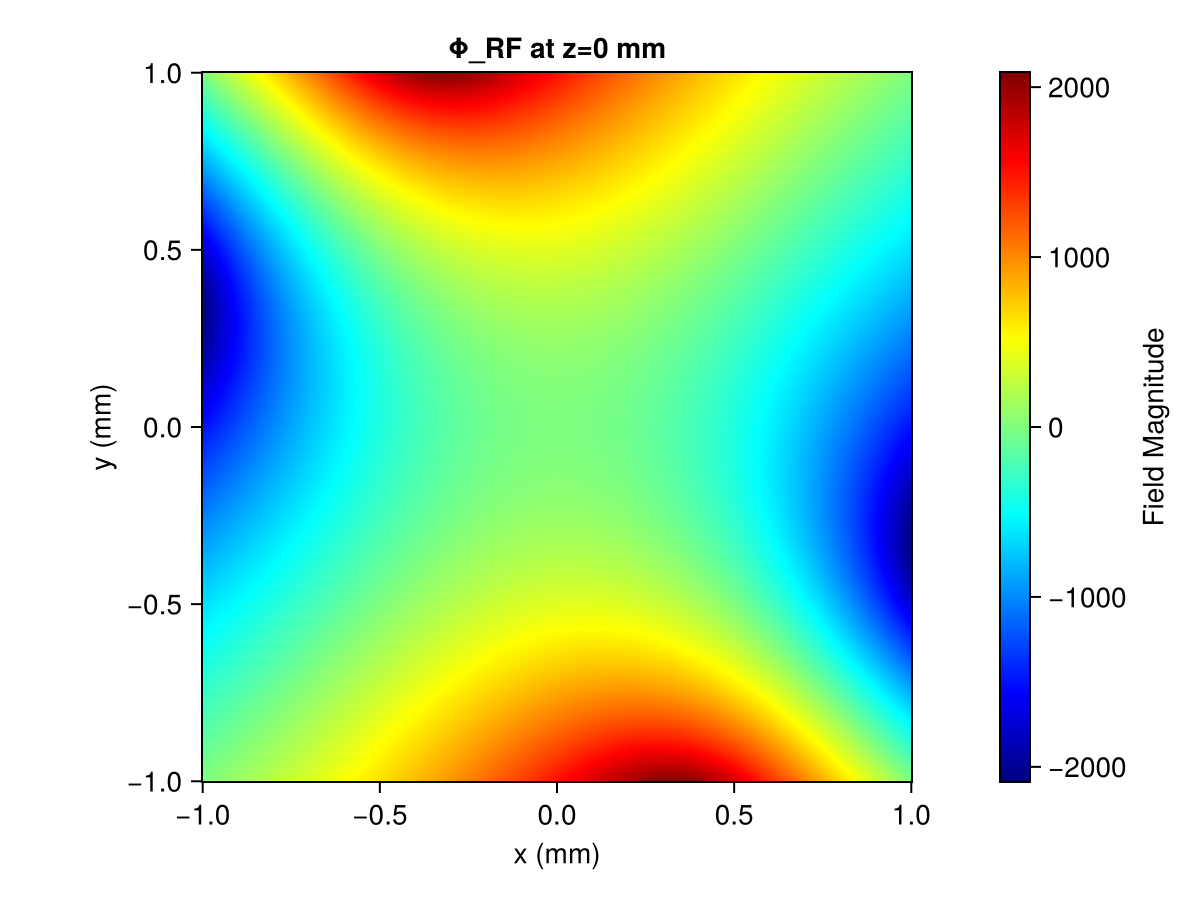

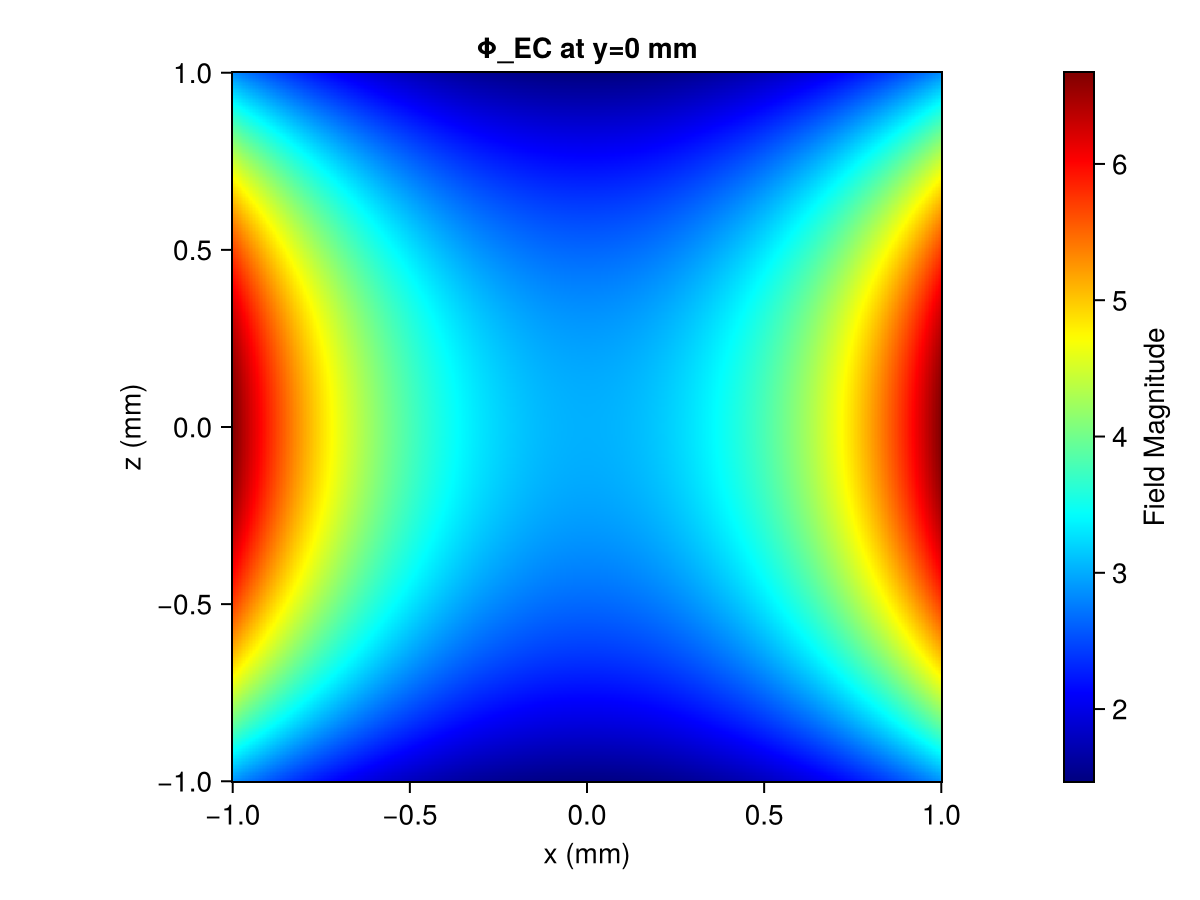

In [ ]:
xs = LinRange(-1e-3, 1e-3, 500); nx = size(xs, 1); Δx = step(xs);
ys = LinRange(-1e-3, 1e-3, 500); ny = size(ys, 1); Δy = step(ys);
zs = LinRange(-1e-3, 1e-3, 500); nz = size(zs, 1); Δz = step(zs);

Φs_grid  = importComsolField3D(nx, ny, nz, "Phis.txt", 2)
    Φ_RF_grid = V_RF/2 .* Φs_grid[:,:,:,1]
    Φ_EC_grid = V_EC .* Φs_grid[:,:,:,2]

plotFieldSlice(xs, ys, Φ_RF_grid[:,:,ceil(Int,nz/2)]; 
    title="Φ_RF at z=0 mm", xlabel="x (mm)", ylabel="y (mm)",
    colormap=:jet);
plotFieldSlice(xs, ys, Φ_EC_grid[:,ceil(Int,ny/2),:]; 
    title="Φ_EC at y=0 mm", xlabel="x (mm)", ylabel="z (mm)",
    colormap=:jet);

Φs_z = Φ_EC_grid[ceil(Int,nx/2) , ceil(Int,ny/2) , :             ]
Φs_x = Φ_RF_grid[:              , ceil(Int,ny/2) , ceil(Int,nz/2)]
Φs_y = Φ_RF_grid[ceil(Int,nx/2) , :              , ceil(Int,nz/2)];

#### Calculate $\eta$ and $\kappa$ *

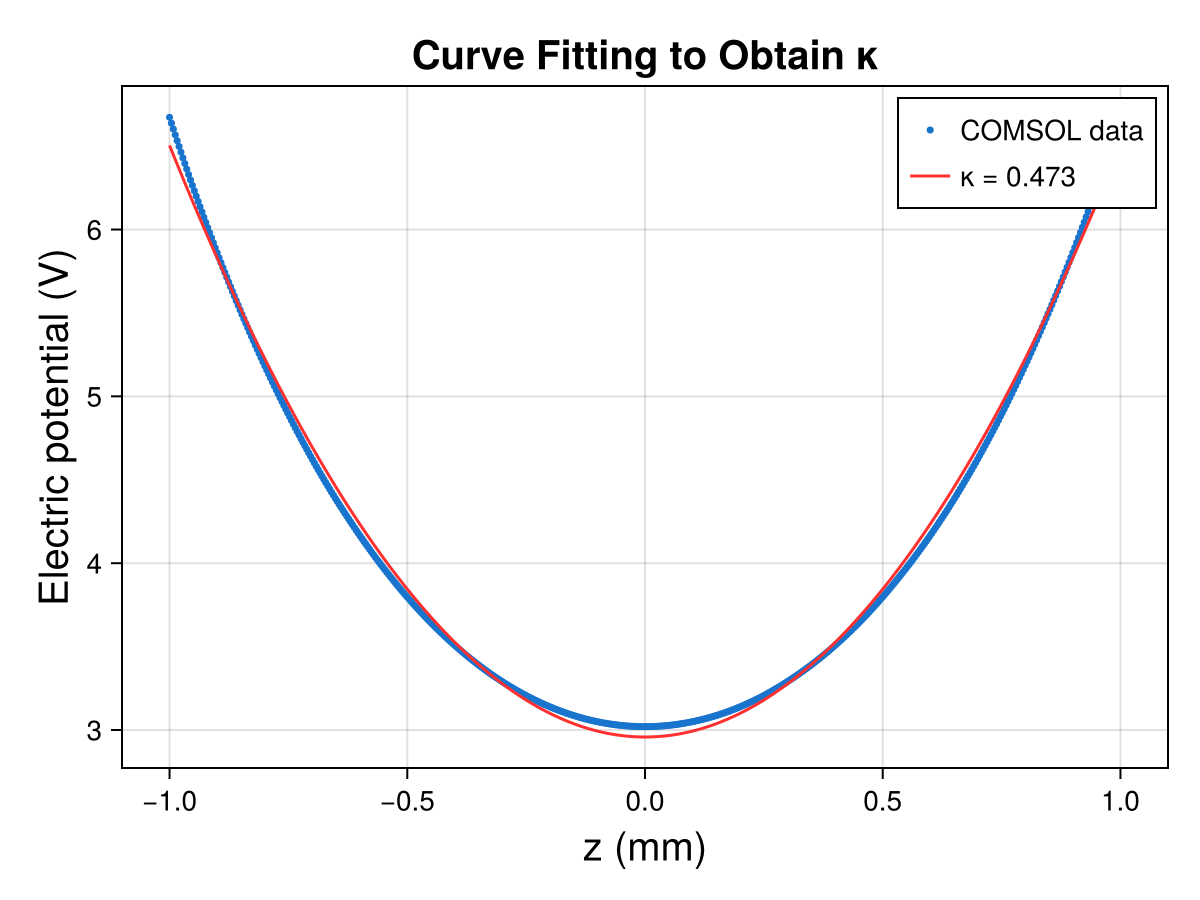

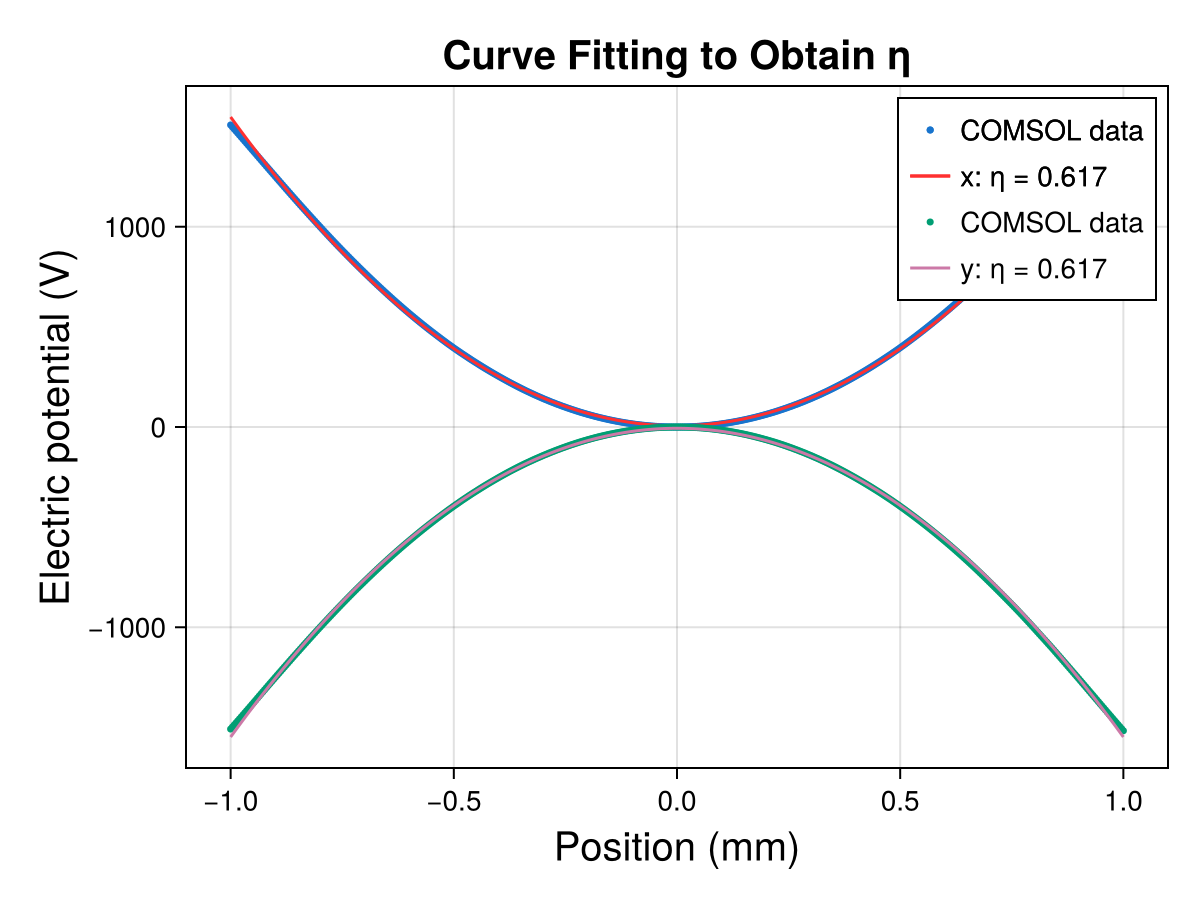

In [ ]:
κ, fig, ax = getEfficiencyFactor("κ", V_EC, collect(zs), Φs_z, z_0, return_fig=true); 
η, fig, ax = getEfficiencyFactor("η", V_RF, [collect(xs),collect(ys)], [Φs_x, Φs_y], r_0, return_fig=true);

#### Execute

In [34]:
# You can use this values to be able to plot the following plots, 
# but otherwise they are calculated as shown above
κ = 0.473
η = 0.617

0.617

### Stability

#### Mathieu parameters

In [8]:
a_x = -(8*Q*V_EC*κ*ϵ)/(M*Ω^2*z_0^2)
a_y = a_x*(1/ϵ-1) 
a_z = -a_x/ϵ

q_x = -(2*Q*V_RF*η)/(M*Ω^2*r_0^2)
q_y = -q_x
q_z = 0 

display(
    DataFrame(
    Parameter = ["a_x", "a_y", "a_z", "q_x", "q_y", "q_z"],
    Value     = [a_x, a_y, a_z, q_x, q_y, q_z]
    )
)

ω_x = Ω/2*sqrt(a_x + q_x^2/2)
ω_y = Ω/2*sqrt(a_y + q_y^2/2)
ω_z = Ω/2*sqrt(a_z)

display(
    DataFrame(
    Parameter = ["ω_x", "ω_y", "ω_z", "γ/2M"],
    Value     = [ω_x, ω_y, ω_z, γ/2M]
    )
)
@show Q_factor = ω_x/(γ/M)
D_r = (Q*V_RF^2*η^2)/(4*M*Ω^2*r_0^2)-κ*V_EC/2*r_0^2/z_0^2;
@show("D_r = $(D_r) V", "U_r = $(Q*D_r*6.2415e18) eV")

Row,Parameter,Value
,String,Float64
1,a_x,-0.00124927
2,a_y,-0.00124927
3,a_z,0.00249853
4,q_x,-0.543085
5,q_y,0.543085
6,q_z,0.0


Row,Parameter,Value
,String,Float64
1,ω_x,6006.56
2,ω_y,6006.56
3,ω_z,785.168
4,γ/2M,2.29832


Q_factor = ω_x / (γ / M) = 1306.728509260559
"D_r = $(D_r) V" = "D_r = 207.51621155530387 V"
"U_r = $(Q * D_r * 6.2415e18) eV" = "U_r = 207515.9093317023 eV"


"U_r = 207515.9093317023 eV"

#### Stability region

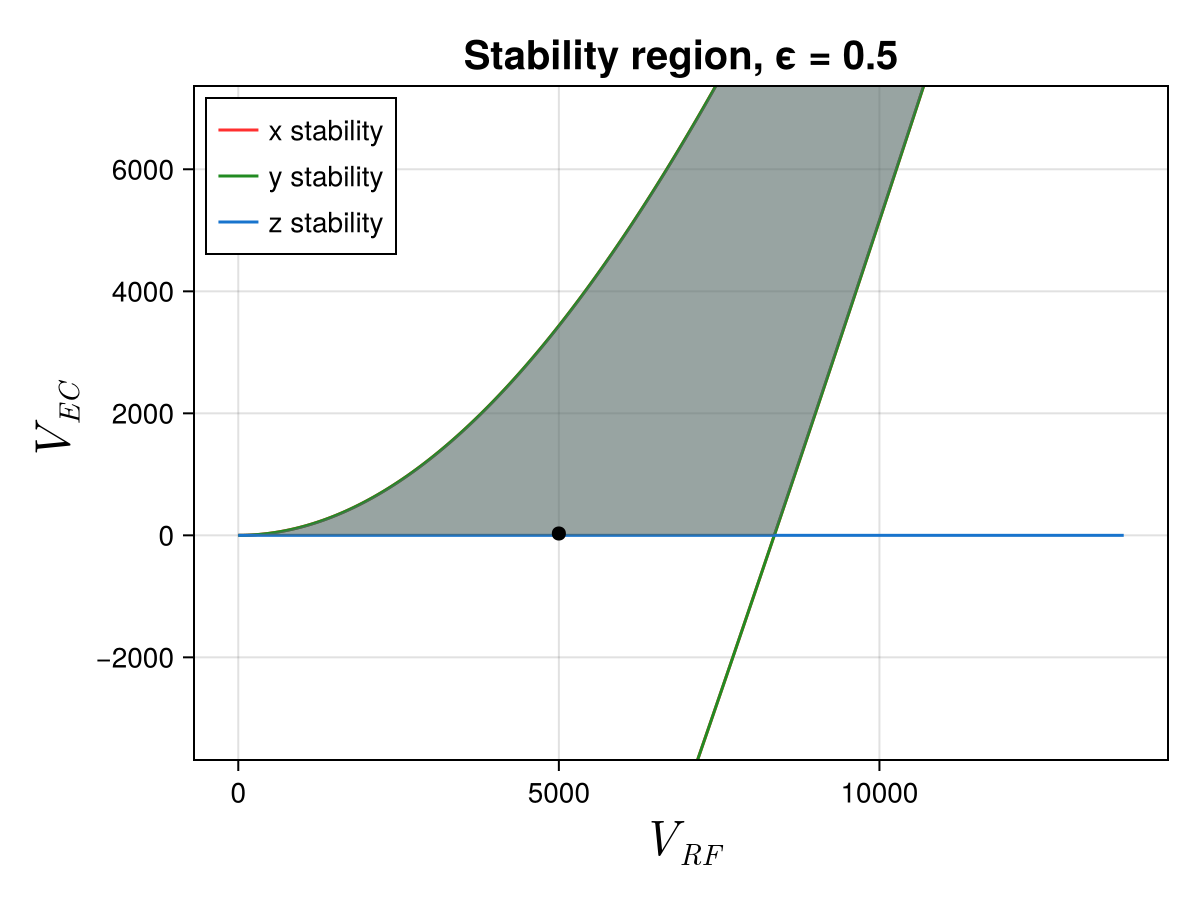

In [20]:
fig, ax = plotStabilityRegion(V_RF, V_EC; M=M, Ω=Ω, z₀=z_0, r₀=r_0, Q=Q, κ=κ, η=η, ϵ=ϵ) 
display(fig); 

#### Parameters map

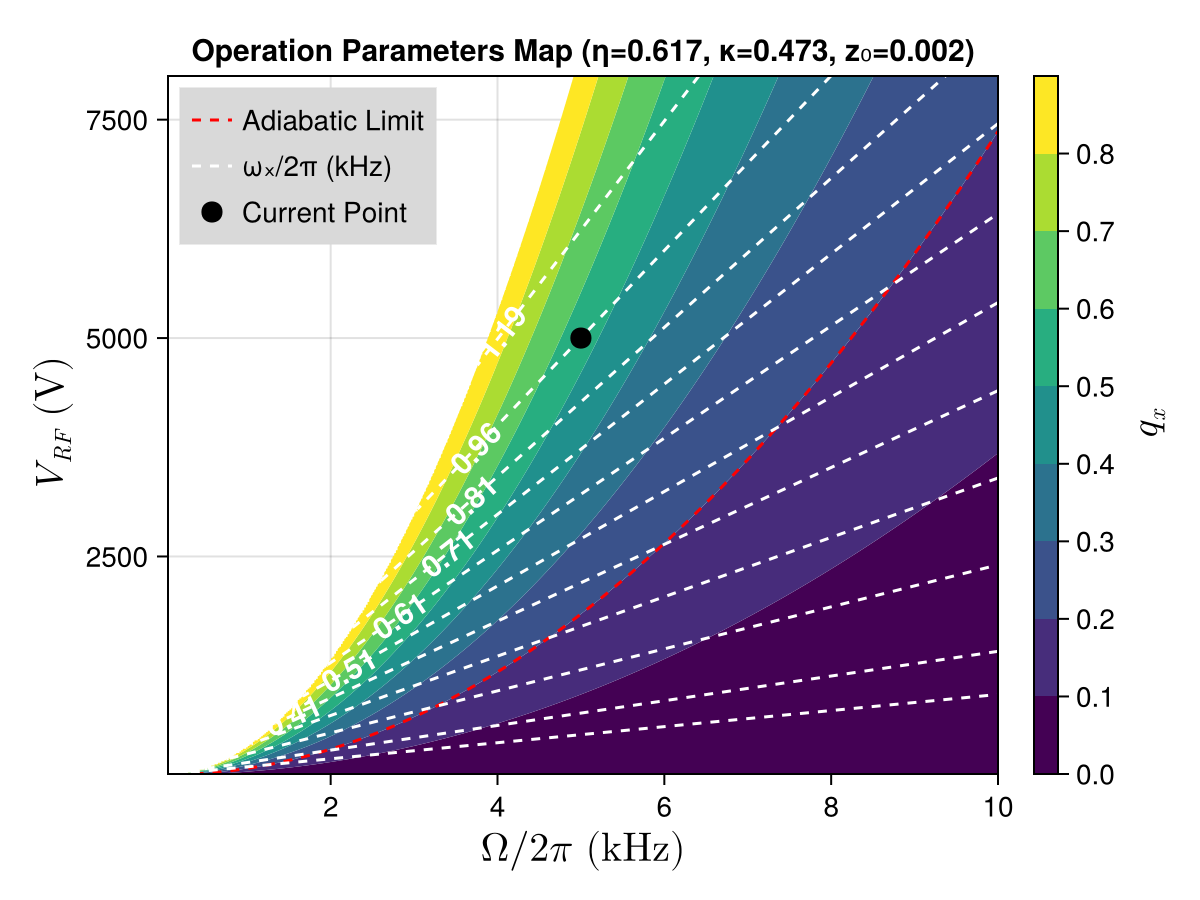

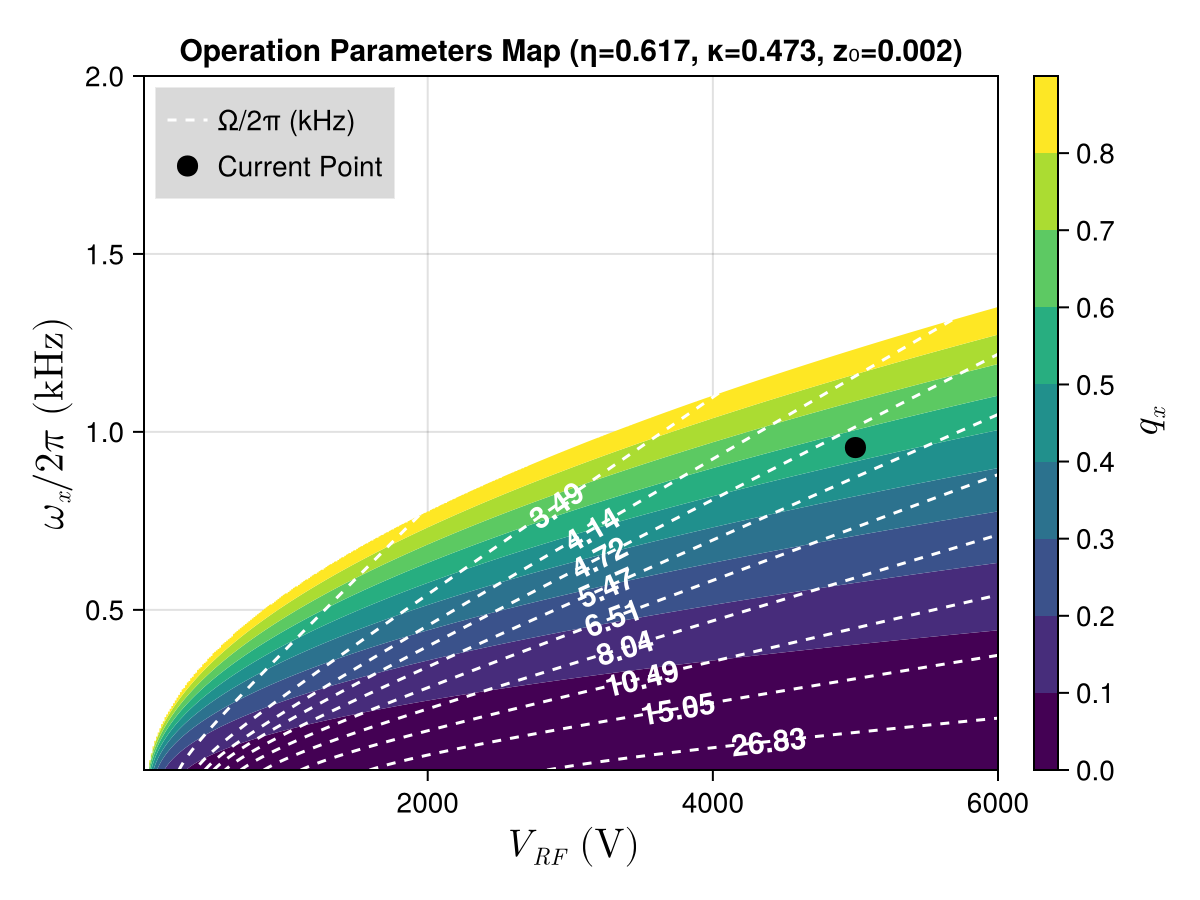

CairoMakie.Screen{IMAGE}


In [ ]:
# The equations used in the tool are defined in the function plotfvsV_RF above
plotfvsV_RF((0.05e3, 10e3), (10, 8e3), Q/M, η, κ, r_0, z_0, V_EC, V_RF, f; 
            interactive=true, Q╱M_range=(1e⁻:1e⁻:2000e⁻)*1e3/M)  
plotf_secvsV_RF((0.05e3, 2e3), (10, 6e3), Q/M, η, κ, r_0, z_0, V_EC, V_RF, ω_x/2π; 
            interactive=true, Q╱M_range=(1e⁻:1e⁻:2000e⁻)*1e3/M)      

## Simulation run *

### Import COMSOL fields

#### Import from file

In [ ]:
xs = LinRange(-3e-3, 3e-3, 500); nx = size(xs, 1); Δx = step(xs); iˣ(x) = Integer(div(x,Δx)+div(nx,2))
ys = LinRange(-3e-3, 3e-3, 500); ny = size(ys, 1); Δy = step(ys); iʸ(y) = Integer(div(y,Δy)+div(ny,2))
zs = LinRange(-3e-3, 3e-3, 500); nz = size(zs, 1); Δz = step(zs); iᶻ(z) = Integer(div(z,Δz)+div(nz,2))

E_RF_grid  = importComsolField3D(nx, ny, nz, "E_RF.txt")
    Ex_RF_grid = E_RF_grid[:,:,:,1] 
    Ey_RF_grid = E_RF_grid[:,:,:,2]
    Ez_RF_grid = E_RF_grid[:,:,:,3] 
E_EC_grid = importComsolField3D(nx, ny, nz, "E_EC.txt")
    Ex_EC_grid = E_EC_grid[:,:,:,1]
    Ey_EC_grid = E_EC_grid[:,:,:,2]
    Ez_EC_grid = E_EC_grid[:,:,:,3]

E_RF_norm = sqrt.(Ex_RF_grid.^2 .+ Ey_RF_grid.^2 .+ Ez_RF_grid.^2);
E_EC_norm = sqrt.((Ex_EC_grid).^2 .+ (Ey_EC_grid).^2 .+ (Ez_EC_grid).^2);

#### Plot slice

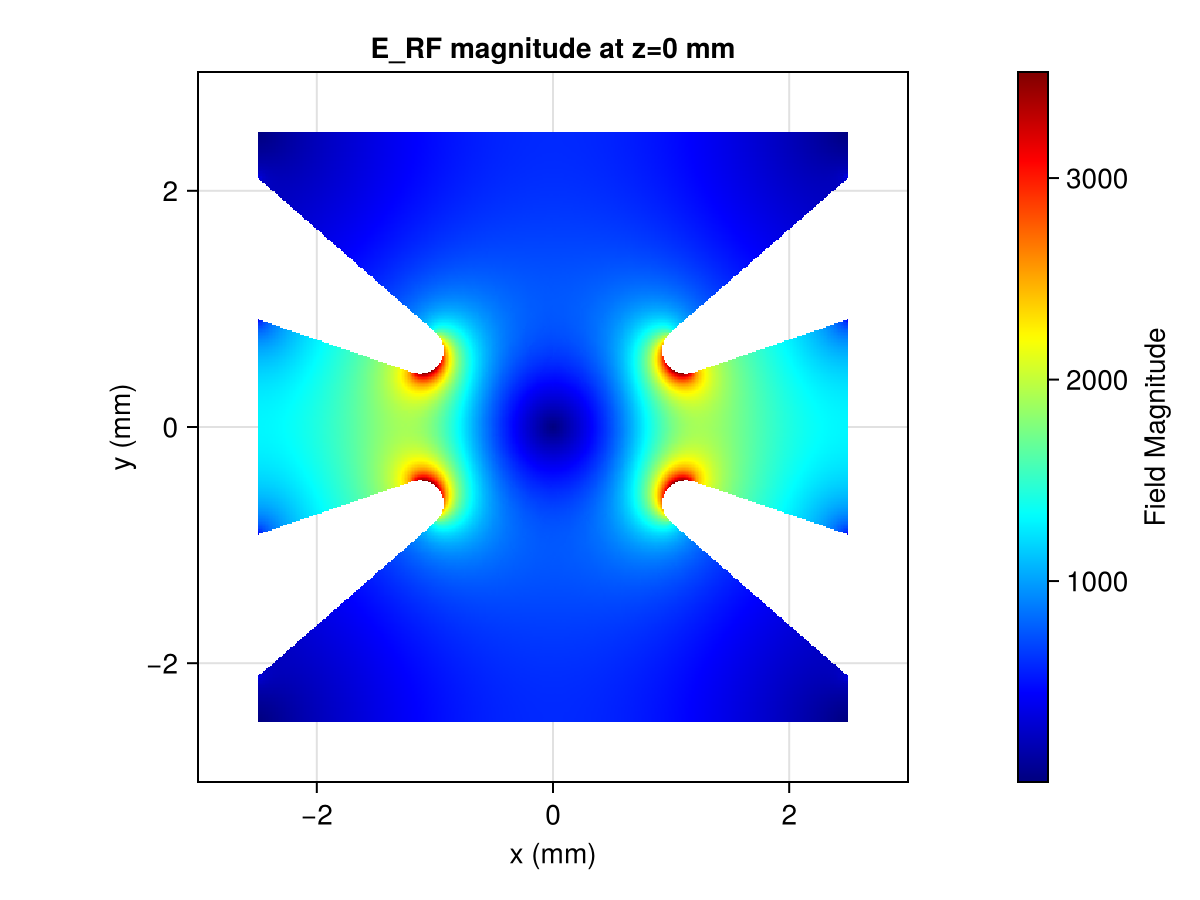

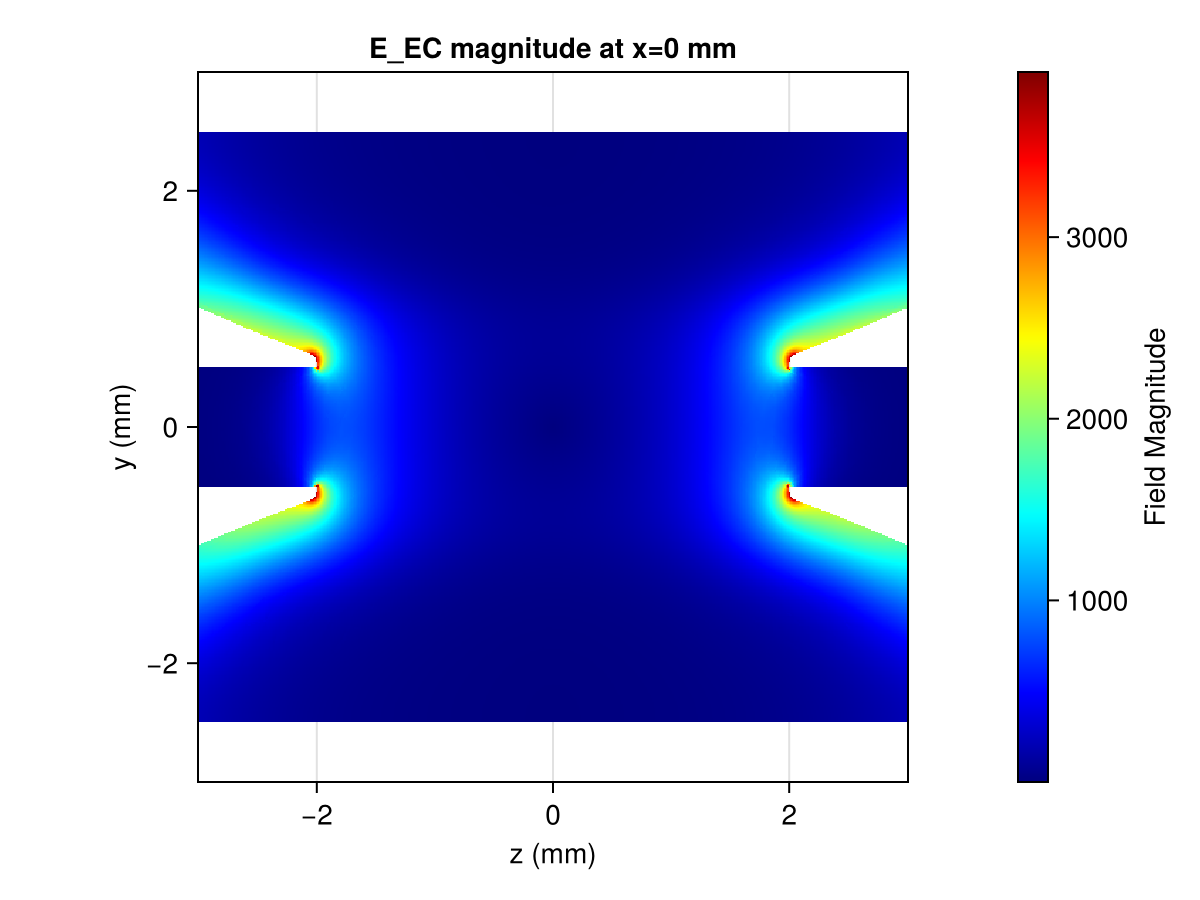

(Scene(2 children, 0 plots), Axis (1 plots))

In [ ]:
plotFieldSlice(xs, ys, E_RF_norm[:,:,iᶻ(0)]; 
    title="E_RF magnitude at z=0 mm", xlabel="x (mm)", ylabel="y (mm)",
    colormap=:jet);
plotFieldSlice(xs, ys, E_EC_norm[iˣ(0),:,:]; 
    title="E_EC magnitude at x=0 mm", xlabel="z (mm)", ylabel="y (mm)",
    colormap=:jet)

#### Interpolate

In [13]:
Ex_RF = Interpolations.scale(interpolate(Ex_RF_grid, BSpline(Linear())), xs, ys, zs);
Ey_RF = Interpolations.scale(interpolate(Ey_RF_grid, BSpline(Linear())), xs, ys, zs);
Ez_RF = Interpolations.scale(interpolate(Ez_RF_grid, BSpline(Linear())), xs, ys, zs);

Ex_EC = Interpolations.scale(interpolate(Ex_EC_grid, BSpline(Linear())), xs, ys, zs);
Ey_EC = Interpolations.scale(interpolate(Ey_EC_grid, BSpline(Linear())), xs, ys, zs);
Ez_EC = Interpolations.scale(interpolate(Ez_EC_grid, BSpline(Linear())), xs, ys, zs);

### Parameters

In [ ]:
g = 9.81 # gravitational acceleration
ĝ = normalize([0.0, -1.0, 0.0])
W = M*g

function F_comsol(r, t) 
    x = r[1]; y = r[2]; z = r[3];
    Fx = Q * (Ex_EC(x, y, z)*V_EC + Ex_RF(x, y, z)*V_RF/2*cos(Ω*t)) + W*ĝ[1]
    Fy = Q * (Ey_EC(x, y, z)*V_EC + Ey_RF(x, y, z)*V_RF/2*cos(Ω*t)) + W*ĝ[2]
    Fz = Q * (Ez_EC(x, y, z)*V_EC + Ez_RF(x, y, z)*V_RF/2*cos(Ω*t)) + W*ĝ[3]
    return [Fx, Fy, Fz]
end

# function F_theory(r, t) 
#     x = r[1]; y = r[2]; z = r[3];
#     Fx = -M * (Ω^2/4*(a_x - 2*q_x*cos(Ω*t))*x) + W*ĝ[1]
#     Fy = -M * (Ω^2/4*(a_y - 2*q_y*cos(Ω*t))*y) + W*ĝ[2]
#     Fz = -M * (Ω^2/4*(a_z)*z) + W*ĝ[3]
#     return [Fx, Fy, Fz]
# end

n_t = 1000000 # time steps
t_total = 1000 / 1000 # total time in seconds
ts = LinRange(0, t_total, n_t); Δt = step(ts)
r₀ = (0.5*r_0)*rand()^(1/3) * normalize(randn(3))
# thermal eq
# v₀ = rand(Normal(0,sqrt(k_b*T/M)), 3)
# falling
v₀ = (W/γ)*ĝ*0;
@show(v₀, r₀, Δt)

v₀ = [0.0, -0.0, 0.0]
r₀ = [-0.00038443739532177006, -3.8689326708234713e-5, -0.0001043689723559797]
Δt = 1.000001000001e-6


1.000001000001e-6

### Run

In [15]:
r_t, v_t = simulate(ts, t_total, r₀, v₀, γ, M, k_b, T, F_comsol);

Progress: 100%|█████████████████████████████████████████| Time: 0:00:060


### Plot results

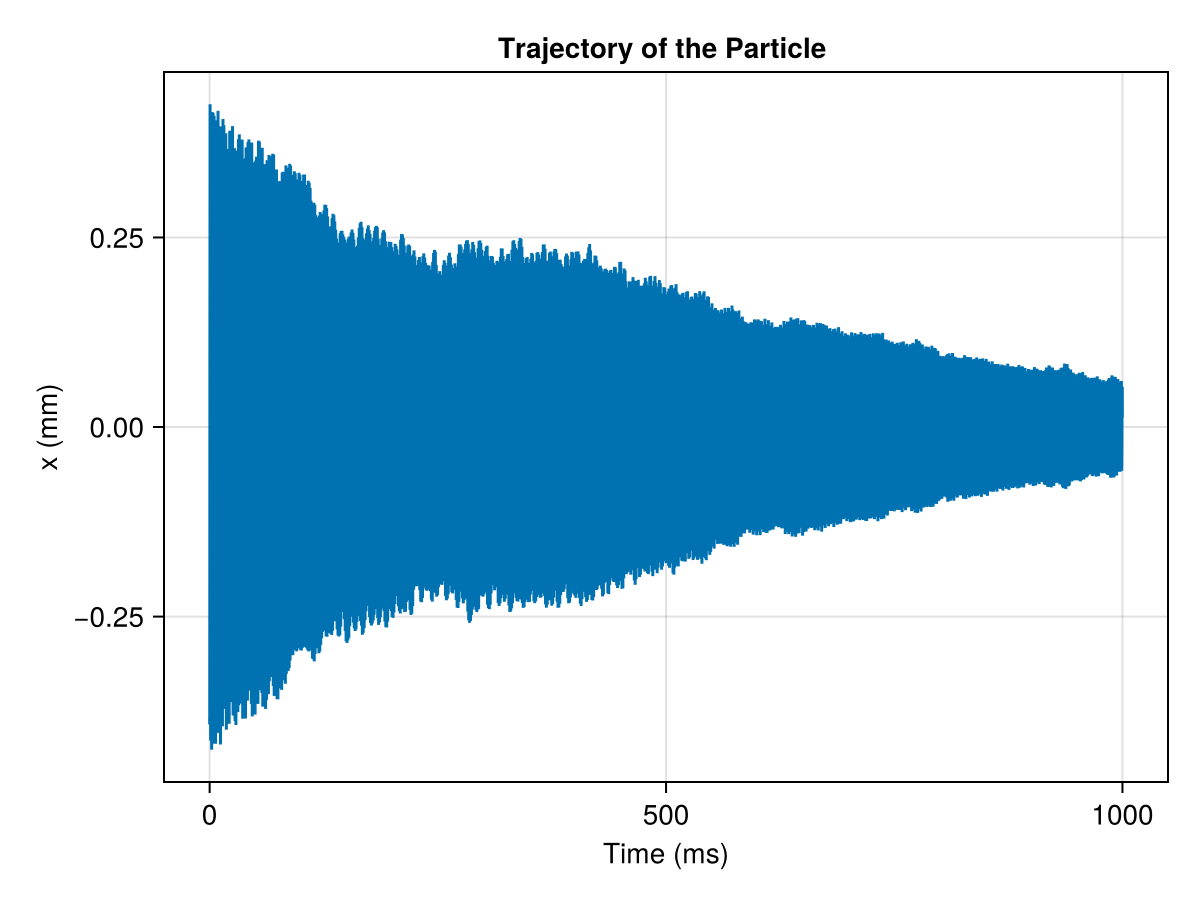

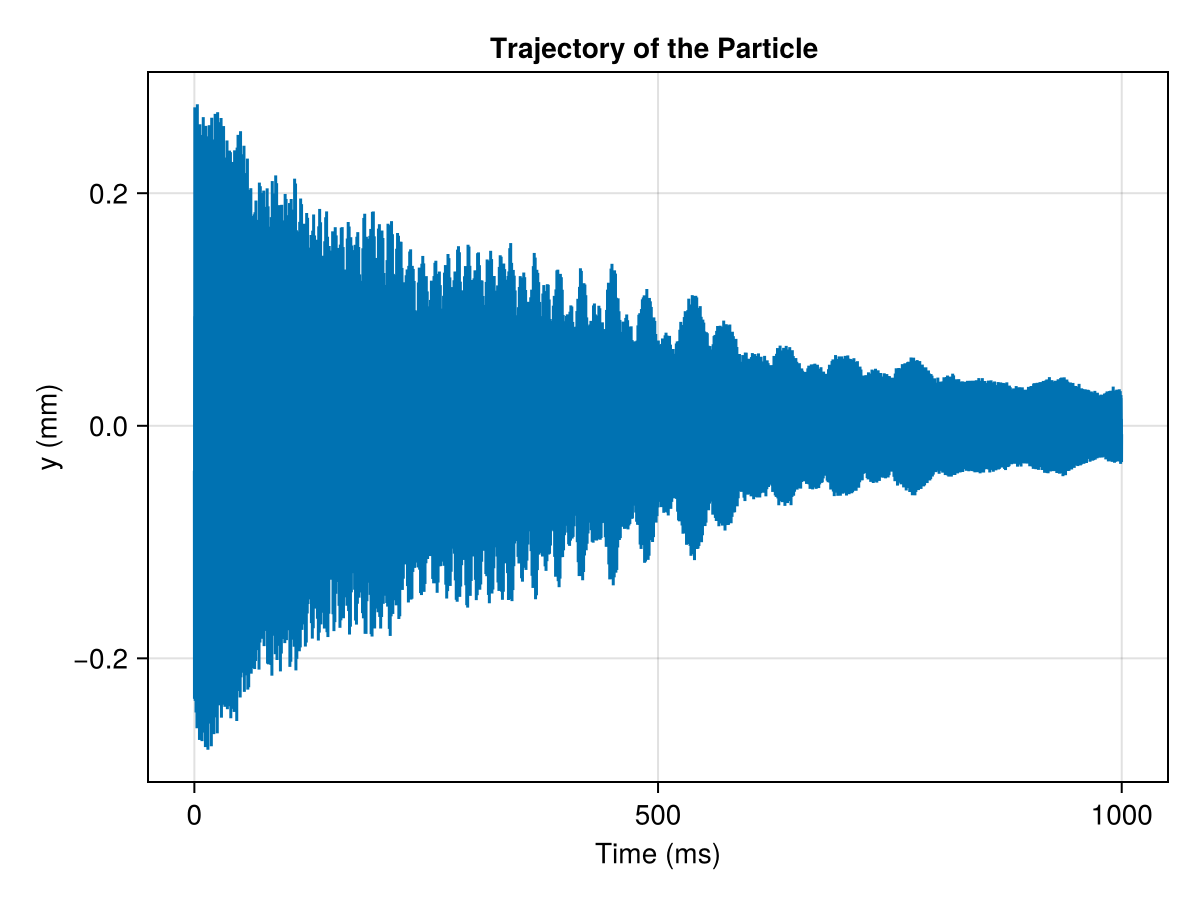

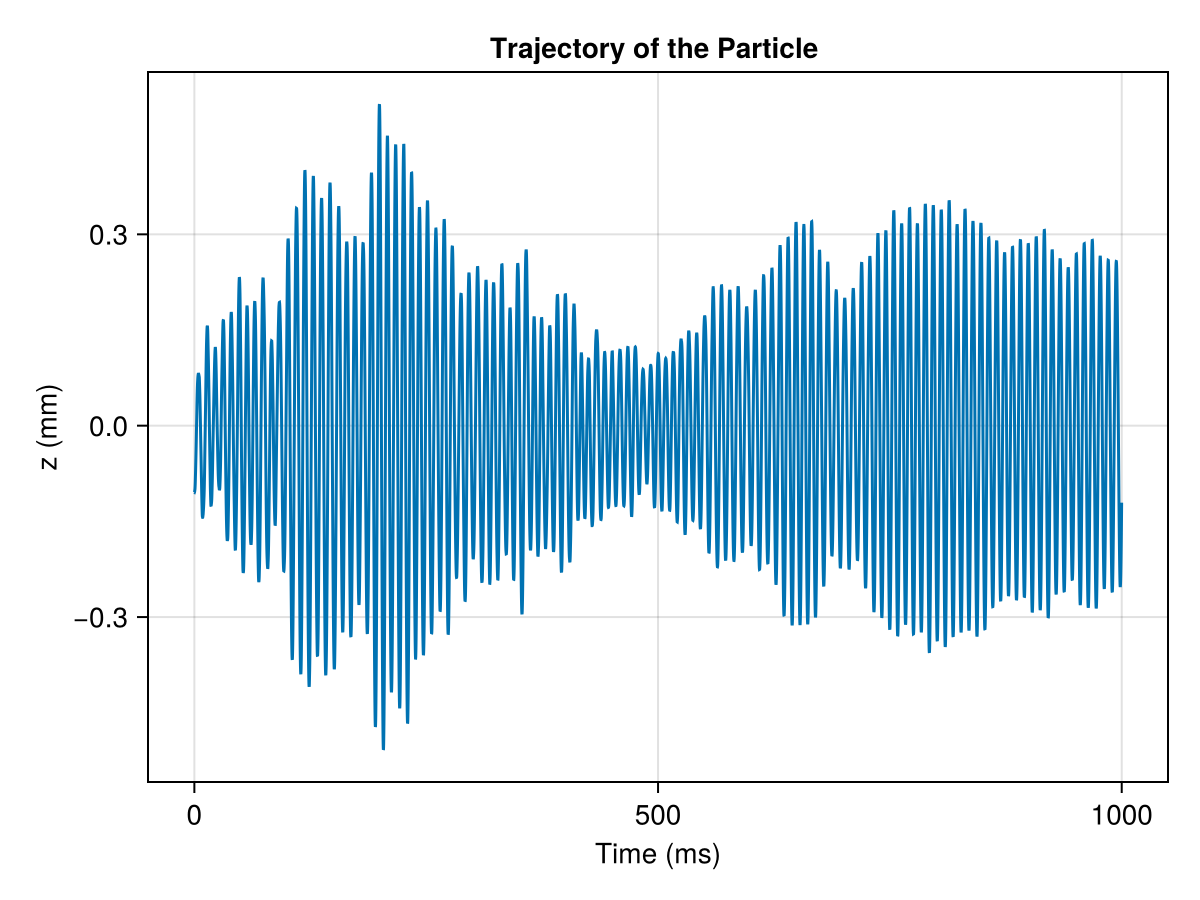

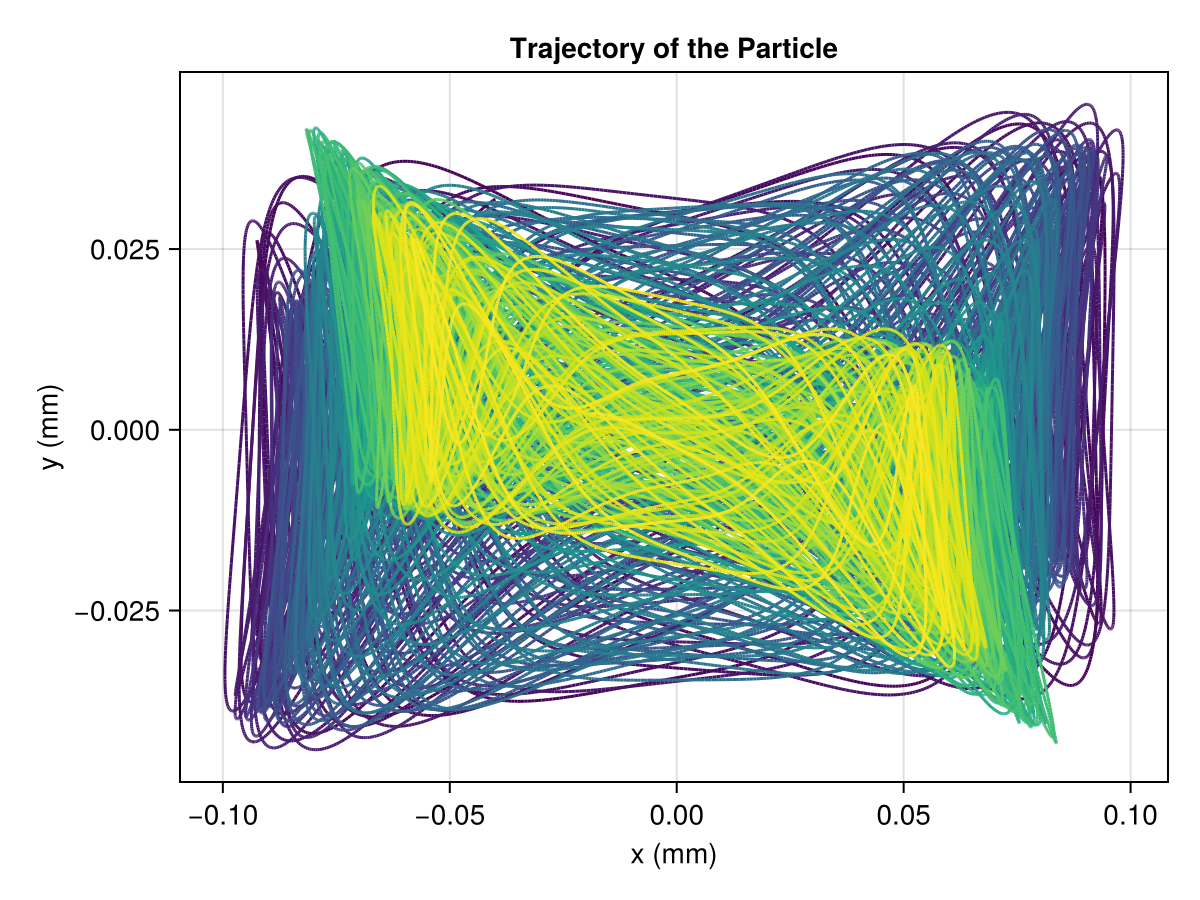

In [16]:
plot3dTraj(r_t; step=100, r₀=r₀, showTrap=true, trap_path="trap_v1.1.stl");
plot1dTraj(r_t[:,1], ts; step=100, dim="x");
plot1dTraj(r_t[:,2], ts; step=100, dim="y");
plot1dTraj(r_t[:,3], ts; step=100, dim="z");
plot2dTraj(r_t[end-n_t÷5:end,:], ts[end-n_t÷5:end], (1, 2); step=1, dimx="x", dimy="y");

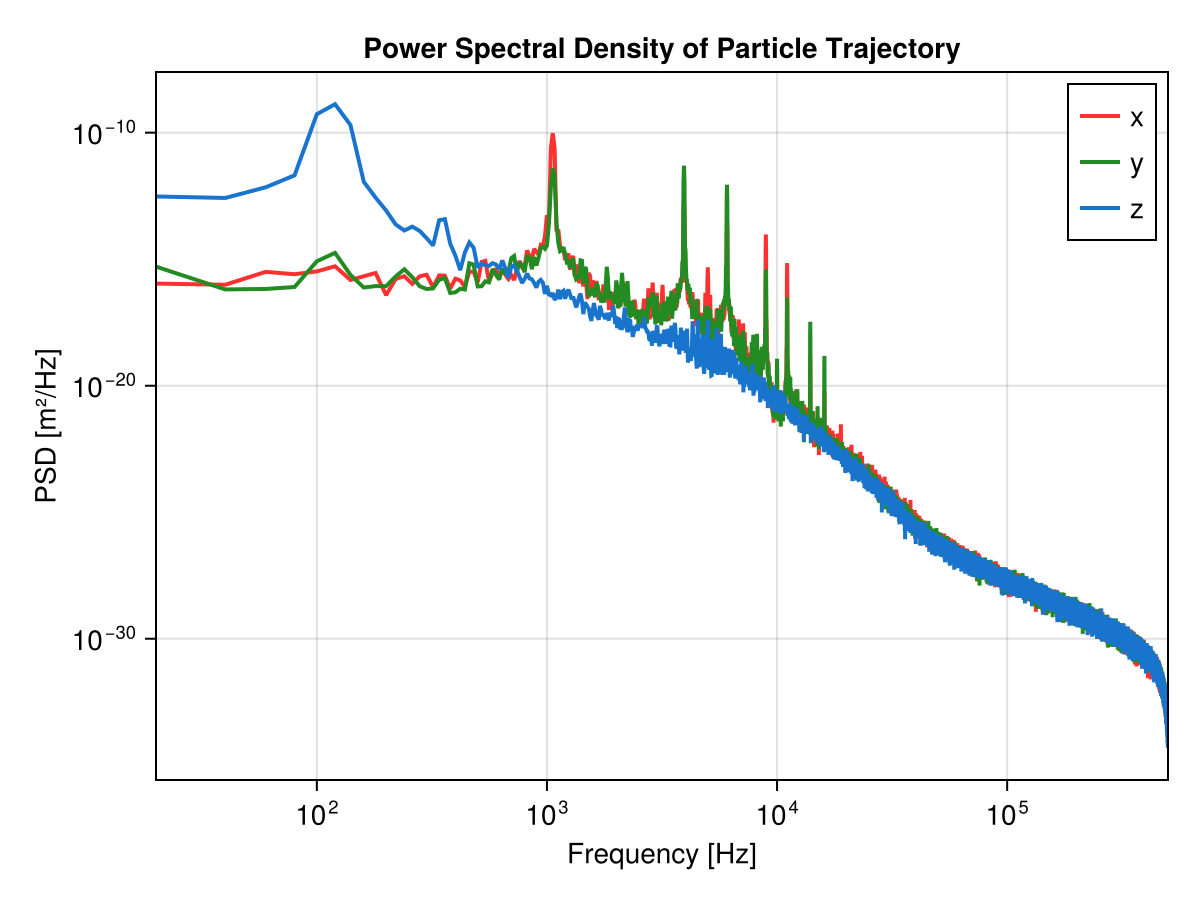

Δf = 5.000 Hz | N_total = 1000000 | N_used = 200000 | método = welch


(Scene(2 children, 0 plots), Axis (3 plots))

In [30]:
freqs, psds = getPSD(r_t, Δt; winlen=n_t÷5)
fig, ax = plotPSD(freqs, psds; step=1)